# 06. 自動グラフレイアウトソルバー（`get_layout()`）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuichi110/drawlib/blob/main/docs/jupyter/ja/06_graph_auto_layout.ipynb)

ノード数が増えると手動での `(x, y)` 座標調整は煩雑になります。`drawlib.graph` は 5 種類の決定的座標ソルバー（`ArchitectureGraph`、`LayerGraph`、`TreeGraph`、`RadialGraph`、`GridGraph`）を提供し、`.xy`（中心座標）、`.bottom_left`（左下座標）、および直交ルーティング済みの `edge.points` を自動算出します。

![LayerGraph.get_layout() で自動配置されたストリーミングデータパイプライン DAG](https://www.drawlib.com/jupyter/images/06_graph_auto_layout/06_hero_layer_graph.png)

*LayerGraph.get_layout() で自動配置されたストリーミングデータパイプライン DAG*

---

## 1. Python セルで自動算出された座標を確認する

ノートブック上では、1 つ目のセルでグラフトポロジを定義して座標を計算し、次のセルでその結果を描画できます。

In [ ]:
!pip install -q drawlib

In [1]:
from drawlib.graph import TreeGraph

tree = TreeGraph(direction="TB", root="platform", default_node_width=28.0, default_node_height=11.0)
tree.child("platform", "compute")
tree.child("platform", "storage")
tree.child("platform", "network")

tree_layout = tree.get_layout(width=116.0, height=46.0, margin=6.0)
for node_id in ("platform", "compute", "storage", "network"):
    node = tree_layout[node_id]
    print(f"{node_id:10s} -> center={node.xy}, bottom_left={node.bottom_left}")

platform   -> center=(58.0, 34.5), bottom_left=(44.0, 29.0)
compute    -> center=(20.0, 11.5), bottom_left=(6.0, 6.0)
storage    -> center=(58.0, 11.5), bottom_left=(44.0, 6.0)
network    -> center=(96.0, 11.5), bottom_left=(82.0, 6.0)


---

## 2. 算出された `TreeGraph` レイアウトの描画

前のセルで計算した `tree_layout` を使って階層ツリーを描画します。

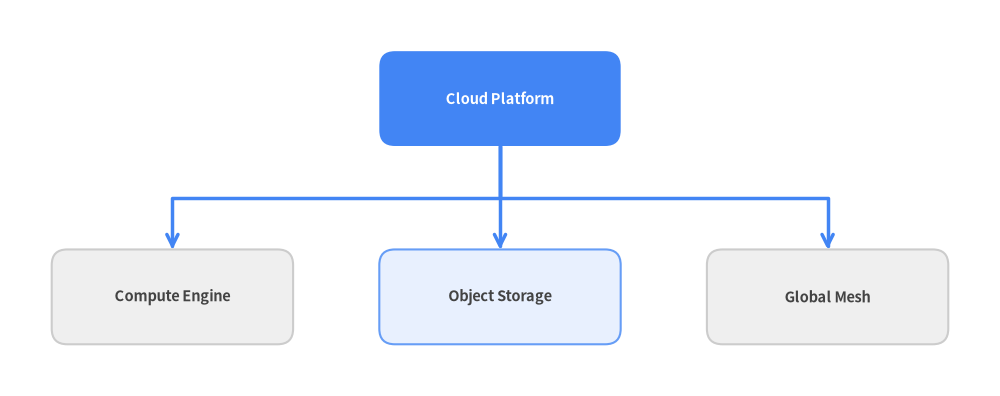

In [2]:
from drawlib.canvas import show, setup
from drawlib.lines import lines
from drawlib.shapes import rectangle
from drawlib.styles import Styles
from drawlib.text import text

setup(width=int(tree_layout.width), height=int(tree_layout.height), cwd=True)

for edge in tree_layout.edges:
    lines(edge.points, arrow_head="->", style=Styles.PrimaryBold)

labels = {
    "platform": ("Cloud Platform", Styles.PrimaryFlat, Styles.WhiteBold),
    "compute": ("Compute Engine", Styles.Neutral, Styles.DarkBold),
    "storage": ("Object Storage", Styles.PrimaryNeutral, Styles.DarkBold),
    "network": ("Global Mesh", Styles.Neutral, Styles.DarkBold),
}

for nid, (label, box_style, txt_style) in labels.items():
    n = tree_layout[nid]
    rectangle(n.xy, width=n.width, height=n.height, style=box_style.patch(shape_r=1.8))
    text(n.xy, label, style=txt_style.patch(text_size=10.5))

show()